# Tahap 11 — perbandingan LSTM, GRU, TCN untuk SO₂ Way Urang

S0 median kausal C30, tanpa Curah Hujan, 48 langkah 30 menit, target t+30 menit original. Empat fold dan pembagian internal sama dengan tahap10. LSTM S0 tahap10 dipakai dari prediksi dan checkpoint tersimpan. GRU/TCN dilatih dalam `.venv-lstm` oleh `scripts/algorithms_stage11.py` dengan checkpoint per epoch dan complete.json per model. Notebook ini membaca dan memeriksa hasil selesai, lalu mengekspor workbook; tidak melatih ulang model. Test akhir tidak dimuat/dievaluasi.

Perintah reproduksi dari root proyek:

```powershell
.venv-lstm\Scripts\python.exe scripts/algorithms_stage11.py
.venv-lstm\Scripts\python.exe scripts/summarize_algorithms_stage11.py
.venv-lstm\Scripts\python.exe scripts/verify_algorithms_stage11.py
```

Script training melewati model yang sudah lengkap dan melanjutkan state optimizer/RNG dari checkpoint epoch terakhir jika proses terputus. Jangan mengubah implementasi atau konfigurasi terkunci, menghapus fold, atau memilih seed dari skor evaluasi.

In [1]:
from pathlib import Path
import sys,json,subprocess
import pandas as pd
from IPython.display import display,Markdown,Image
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
RUN=ROOT/'outputs/perbandingan_algoritma_tahap11'
sys.path.insert(0,str(ROOT/'scripts'))
from audit_quality import hashfile
cfg=json.loads((RUN/'config_locked.json').read_text(encoding='utf-8'))
t=json.loads((RUN/'tabel_hasil.json').read_text(encoding='utf-8'))
checks=json.loads((RUN/'checks.json').read_text(encoding='utf-8'))
assert checks['new_completed_models']==24 and checks['old_lstm_reference_models']==12
assert not cfg['test_loaded'] and not cfg['test_evaluated']
print('SHA256 konfigurasi:',hashfile(RUN/'config_locked.json'))
print('Lingkungan:',cfg['environment'])
print('Kanal S0:',cfg['features'])
print('Uji kausalitas TCN:',cfg['causal_test'])
display(pd.DataFrame(t['Gate_sebelum_fit']))


SHA256 konfigurasi: 63b680d82cb7cf753824f2532ba9ce76d1695a415530790b23724c00467b54b0
Lingkungan: {'python': '3.12.14 (main, Aug 25 2026, 14:01:42) [MSC v.1944 64 bit (AMD64)]', 'executable': 'C:\\Users\\INTAN\\airpollutan_SO2\\.venv-lstm\\Scripts\\python.exe', 'platform': 'Windows-11-10.0.26300-SP0', 'device': 'cpu', 'cuda_available': False, 'torch_cuda_build': None, 'torch_threads': 1, 'deterministic_algorithms': True, 'versions': {'torch': '2.15.0+cpu', 'numpy': '2.5.4', 'pandas': '3.1.1', 'scikit-learn': '1.9.1', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'ipykernel': '7.4.0'}}
Kanal S0: ['SO2_origin', 'PM10_lag1', 'PM2.5_lag1', 'CO_lag1', 'O3_lag1', 'NO2_lag1', 'Kec.Angin_lag1', 'Kelembaban_lag1', 'Suhu_lag1', 'Tek.Udara_lag1', 'Sol.Rad_lag1', 'missing_asli_SO2_origin', 'missing_asli_PM10_lag1', 'missing_asli_PM2.5_lag1', 'missing_asli_CO_lag1', 'missing_asli_O3_lag1', 'missing_asli_NO2_lag1', 'missing_asli_Kec.Angin_lag1', 'missing_asli_Kelembaban_lag1', 'missing_asli_Suhu_lag1', 

,Fold,Train N,Internal N,Evaluasi N,Stage10 S0 train cocok,Stage10 S0 internal cocok,Stage10 S0 evaluasi cocok,Fitur kanal,Fitur terverifikasi,Target asli,Scaler train internal,Fit baru sebelum gate,Lulus,Train akhir kalender,Internal mulai kalender,Internal akhir kalender,Evaluasi mulai kalender,Evaluasi akhir kalender
0,Fold_01,2679,860,4890,True,True,True,22,True,True,True,0,True,2025-04-12 23:30:00,2025-04-13 00:00:00,2025-04-30 23:30:00,2025-05-01 00:00:00,2025-08-12 13:30:00
1,Fold_02,6822,1607,4969,True,True,True,22,True,True,True,0,True,2025-07-10 00:30:00,2025-07-10 01:00:00,2025-08-12 13:30:00,2025-08-12 14:00:00,2025-11-24 03:00:00
2,Fold_03,11042,2356,4969,True,True,True,22,True,True,True,0,True,2025-10-06 01:00:00,2025-10-06 01:30:00,2025-11-24 03:00:00,2025-11-24 03:30:00,2026-03-07 16:30:00
3,Fold_04,15267,3100,4969,True,True,True,22,True,True,True,0,True,2026-01-02 01:30:00,2026-01-02 02:00:00,2026-03-07 16:30:00,2026-03-07 17:00:00,2026-06-19 06:00:00


## Input dan pembagian setara

Tensor S0 tahap10, scaler numerik/target, median prefix train internal, 11 indikator missing asli, serta timestamp tiga bagian dipakai ulang dan diverifikasi. Train/internal/evaluasi sama untuk LSTM, GRU dan TCN. Target evaluasi asli; persistence memakai SO₂ asli terakhir pada/sebelum origin. TCN memangkas keluaran padding kanan sehingga tidak melihat langkah sesudah origin. Anggaran training serupa tidak menyetarakan jumlah parameter, epoch atau optimisasi.

In [2]:
display(pd.DataFrame(t['Distribusi_target']))
display(pd.DataFrame(t['Waktu_dan_parameter']))
display(pd.DataFrame(t['Ringkas_waktu']))
print('GRU lengkap',len(list(RUN.glob('Fold_*/GRU_seed*/complete.json'))),'TCN lengkap',len(list(RUN.glob('Fold_*/TCN_seed*/complete.json'))))


GRU lengkap 12 TCN lengkap 12


,Fold,Bagian,Awal target,Akhir target,Minimum,P1,P25,Median,P75,P99,Maksimum,N,Mean,SD,SO2 lebih2.14
0,Fold_01,inner_train,2025-02-13 19:00:00,2025-04-12 23:30:00,1.24,1.3300,1.45,45.15,45.80,77.6454,80.71,2679,36.231391,22.398111,1972
1,Fold_01,inner_validation,2025-04-13 00:00:00,2025-04-30 23:30:00,43.72,43.9977,45.02,45.45,45.84,46.8946,47.29,860,45.436721,0.619540,860
2,Fold_01,evaluation,2025-05-01 00:00:00,2025-08-12 13:30:00,1.07,1.2500,1.56,43.85,45.38,46.7411,47.81,4890,23.580558,21.929684,2456
3,Fold_02,inner_train,2025-02-13 19:00:00,2025-07-10 00:30:00,1.07,1.3200,44.24,45.18,45.74,76.2800,80.71,6822,36.490716,19.592455,5288
4,Fold_02,inner_validation,2025-07-10 01:00:00,2025-08-12 13:30:00,1.08,1.2300,1.49,1.56,1.63,1.9000,2.10,1607,1.561133,0.121993,0
5,Fold_02,evaluation,2025-08-12 14:00:00,2025-11-24 03:00:00,1.04,1.1900,1.48,1.56,1.64,1.9132,2.14,4969,1.560920,0.131798,0
6,Fold_03,inner_train,2025-02-13 19:00:00,2025-10-06 01:00:00,1.04,1.2841,1.54,1.76,45.39,75.4518,80.71,11042,23.141342,22.918635,5288
7,Fold_03,inner_validation,2025-10-06 01:30:00,2025-11-24 03:00:00,1.04,1.1800,1.47,1.56,1.65,1.9400,2.07,2356,1.561087,0.143811,0
8,Fold_03,evaluation,2025-11-24 03:30:00,2026-03-07 16:30:00,1.08,1.2100,1.49,1.56,1.63,1.9300,2.04,4969,1.562727,0.128728,0
9,Fold_04,inner_train,2025-02-13 19:00:00,2026-01-02 01:30:00,1.04,1.2400,1.52,1.64,45.05,74.7100,80.71,15267,17.170152,21.750593,5288


,Fold,Algoritma,Seed,Sumber,Epoch dijalankan,Epoch terbaik,Internal MSE standar terbaik,Fit early stopping detik,Predict detik,Jumlah parameter,N train,N internal,Checkpoint SHA256,Path checkpoint
0,Fold_01,LSTM,11,checkpoint tahap10 S0,25,17,0.000797,30.123244,0.721320,7201,2679,860,a15e3a680b608855f821d678a0db236c999a8d078ef575...,outputs/lstm_antarstasiun_tahap10/Fold_01/S0_s...
1,Fold_01,GRU,11,fit baru tahap11,50,42,0.000858,91.005421,0.241116,5409,2679,860,c228462979f3d0ce0f8c356071855e0b5e752479656846...,outputs/perbandingan_algoritma_tahap11/Fold_01...
2,Fold_01,TCN,11,fit baru tahap11,40,32,0.001127,73.733903,0.777790,6945,2679,860,30f89495c9539f6561beec45b162a4de70b9bbf558bd1b...,outputs/perbandingan_algoritma_tahap11/Fold_01...
3,Fold_01,LSTM,23,checkpoint tahap10 S0,27,19,0.000803,31.895839,0.789712,7201,2679,860,32e1882f4bbc398a8b05a9fbd12f1c39d91c778e316a3e...,outputs/lstm_antarstasiun_tahap10/Fold_01/S0_s...
4,Fold_01,GRU,23,fit baru tahap11,37,29,0.000933,67.462608,0.474902,5409,2679,860,affe5bfe8f0f0c609633a1c154675b0d411e71698985dd...,outputs/perbandingan_algoritma_tahap11/Fold_01...
5,Fold_01,TCN,23,fit baru tahap11,43,35,0.001008,79.948146,0.925899,6945,2679,860,fabc598413ebf0d1158740661bb3b8d5c0840707247160...,outputs/perbandingan_algoritma_tahap11/Fold_01...
6,Fold_01,LSTM,47,checkpoint tahap10 S0,44,36,0.000815,51.430627,0.754926,7201,2679,860,3341dfea87fea567be4ca3854434d670710ff00bca1e9e...,outputs/lstm_antarstasiun_tahap10/Fold_01/S0_s...
7,Fold_01,GRU,47,fit baru tahap11,47,39,0.000926,98.470168,0.563847,5409,2679,860,3fe5fa5612582c22578752302065d8dec3349964d7c647...,outputs/perbandingan_algoritma_tahap11/Fold_01...
8,Fold_01,TCN,47,fit baru tahap11,42,34,0.000935,74.336958,0.942287,6945,2679,860,a8099ce9db21d9cea38ff8493fe796c2f015def90c0b29...,outputs/perbandingan_algoritma_tahap11/Fold_01...
9,Fold_02,LSTM,11,checkpoint tahap10 S0,16,8,0.001217,42.021976,0.162449,7201,6822,1607,9c70a63c0066d1fd264d469f7a2b3d847e3b0026336384...,outputs/lstm_antarstasiun_tahap10/Fold_02/S0_s...


,Algoritma,Model N,Jumlah parameter,Epoch total,Epoch median,Fit total detik,Fit median detik,Predict total detik
0,LSTM,12,7201,403,33.0,1720.992834,145.731866,8.076428
1,GRU,12,5409,493,44.5,2988.276425,256.406870,5.601153
2,TCN,12,6945,466,41.0,2430.616222,147.746839,9.530204


## Error asli per fold, seed, bulan dan gabungan

MAE/RMSE/bias dalam µg/m³ setelah inverse target scaling. Gabungan dihitung ulang dari error OOF per seed; SD antar-seed ddof1. Semua skor perbandingan domain bersama memakai timestamp yang identik. Skor mandiri dan cakupan terhadap seluruh target asli juga disimpan.

In [3]:
for name in ['Skor_fold_seed','Gabungan_per_seed','Ringkasan','Vs_persistence','Skor_bulanan']:
    print(name);display(pd.DataFrame(t[name]))


Skor_fold_seed
Gabungan_per_seed
Ringkasan
Vs_persistence
Skor_bulanan


,Fold,Seed,Algoritma,Domain,N,Denominator target asli,Cakupan persen,MAE,RMSE,Bias,Prediksi negatif,SHA256 timestamp
0,Fold_01,11,LSTM,mandiri,4890,4890,100.0,14.088429,20.431628,13.834207,0,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
1,Fold_01,11,LSTM,bersama,4890,4890,100.0,14.088429,20.431628,13.834207,0,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
2,Fold_01,11,GRU,mandiri,4890,4890,100.0,19.609663,28.138338,19.351973,0,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
3,Fold_01,11,GRU,bersama,4890,4890,100.0,19.609663,28.138338,19.351973,0,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
4,Fold_01,11,TCN,mandiri,4890,4890,100.0,328.367711,489.640110,328.118681,0,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
...,...,...,...,...,...,...,...,...,...,...,...,...
91,Fold_04,47,GRU,bersama,4969,4969,100.0,0.143443,0.222042,0.099806,0,43cde718d85be72d2a1b783dfb4909258f1c10f2f86628...
92,Fold_04,47,TCN,mandiri,4969,4969,100.0,0.116785,0.158830,0.010701,2,43cde718d85be72d2a1b783dfb4909258f1c10f2f86628...
93,Fold_04,47,TCN,bersama,4969,4969,100.0,0.116785,0.158830,0.010701,2,43cde718d85be72d2a1b783dfb4909258f1c10f2f86628...
94,Fold_04,47,Persistence,mandiri,4969,4969,100.0,0.115935,0.149092,0.000024,0,43cde718d85be72d2a1b783dfb4909258f1c10f2f86628...


,Fold,Seed,Algoritma,Domain,N,Denominator target asli,Cakupan persen,MAE,RMSE,Bias,Prediksi negatif,SHA256 timestamp
0,Gabungan_OOF,11,LSTM,mandiri,19797,19797,100.0,3.723031,10.169410,3.511675,26,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
1,Gabungan_OOF,11,LSTM,bersama,19797,19797,100.0,3.723031,10.169410,3.511675,26,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
2,Gabungan_OOF,11,GRU,mandiri,19797,19797,100.0,5.029779,13.989556,4.806089,41,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
3,Gabungan_OOF,11,GRU,bersama,19797,19797,100.0,5.029779,13.989556,4.806089,41,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
4,Gabungan_OOF,11,TCN,mandiri,19797,19797,100.0,81.570727,243.352588,81.275417,311,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
5,Gabungan_OOF,11,TCN,bersama,19797,19797,100.0,81.570727,243.352588,81.275417,311,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
6,Gabungan_OOF,11,Persistence,mandiri,19797,19797,100.0,0.206335,0.464340,0.002240,0,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
7,Gabungan_OOF,11,Persistence,bersama,19797,19797,100.0,0.206335,0.464340,0.002240,0,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
8,Gabungan_OOF,23,LSTM,mandiri,19797,19797,100.0,4.181421,10.894457,3.996841,60,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
9,Gabungan_OOF,23,LSTM,bersama,19797,19797,100.0,4.181421,10.894457,3.996841,60,1663821d30ee4523fd8c636c175f3570cf6976594a170f...


,Fold,Algoritma,Domain,Seed N,MAE mean,MAE SD seed,RMSE mean,RMSE SD seed,Bias mean,Bias SD seed,Cakupan persen mean,Cakupan persen SD seed,Prediksi negatif mean,Prediksi negatif SD seed
0,Fold_01,LSTM,bersama,3,16.317958,2.744570e+00,23.290559,3.778002,16.057695,2.746188,100.0,0.0,0.000000,0.000000
1,Fold_01,GRU,bersama,3,16.339682,3.239079e+00,23.729290,4.359752,16.069055,3.240829,100.0,0.0,0.333333,0.577350
2,Fold_01,TCN,bersama,3,244.639822,7.821093e+01,368.756432,113.648288,244.317615,78.299113,100.0,0.0,4.333333,7.505553
3,Fold_01,Persistence,bersama,3,0.430562,0.000000e+00,0.885256,0.000000,0.009049,0.000000,100.0,0.0,0.000000,0.000000
4,Fold_02,LSTM,bersama,3,0.861119,2.529122e-01,1.158641,0.298598,0.526030,0.392686,100.0,0.0,55.666667,34.004902
5,Fold_02,GRU,bersama,3,0.657119,1.583177e-01,0.897977,0.185486,0.005168,0.430053,100.0,0.0,219.666667,305.139859
6,Fold_02,TCN,bersama,3,1.374927,3.589187e-01,1.863585,0.483795,-0.013871,0.943004,100.0,0.0,863.666667,813.396787
7,Fold_02,Persistence,bersama,3,0.142954,0.000000e+00,0.183682,0.000000,-0.000020,0.000000,100.0,0.0,0.000000,0.000000
8,Fold_03,LSTM,bersama,3,0.127222,6.897712e-03,0.196692,0.031285,-0.003355,0.020411,100.0,0.0,3.000000,1.732051
9,Fold_03,GRU,bersama,3,0.151984,2.742789e-02,0.204694,0.040504,0.030639,0.053036,100.0,0.0,1.666667,2.886751


,Fold,Seed,Algoritma,N identik,Delta MAE vs persistence,Delta RMSE vs persistence,Perbaikan MAE persen,Perbaikan RMSE persen
0,Fold_01,11,LSTM,4890,13.657867,19.546372,-3172.099423,-2207.991490
1,Fold_01,11,GRU,4890,19.179101,27.253082,-4454.430370,-3078.554512
2,Fold_01,11,TCN,4890,327.937148,488.754854,-76164.841471,-55210.579817
3,Fold_01,23,LSTM,4890,15.051631,20.981143,-3495.807439,-2370.065552
4,Fold_01,23,GRU,4890,15.846404,22.743713,-3680.396829,-2569.168545
5,Fold_01,23,TCN,4890,231.657094,351.659256,-53803.376569,-39724.027874
6,Fold_01,47,LSTM,4890,18.952690,26.688395,-4401.845428,-3014.766556
7,Fold_01,47,GRU,4890,12.701855,18.535309,-2950.061475,-2093.780005
8,Fold_01,47,TCN,4890,173.033536,263.199418,-40187.797834,-29731.454040
9,Fold_02,11,LSTM,4969,0.591868,0.889892,-414.026064,-484.475054


,Bulan target,Fold,Seed,Algoritma,Domain,N,Denominator target asli,Cakupan persen,MAE,RMSE,Bias,Prediksi negatif,SHA256 timestamp
0,2025-05,Fold_01,11,LSTM,mandiri,1413,1413,100.0,0.501558,0.622960,-0.007271,0,9be19d4abf64d53a705b02b6d3716b4dac9b909cbc1b92...
1,2025-06,Fold_01,11,LSTM,mandiri,1440,1440,100.0,8.163339,15.320655,7.799332,0,2dab8e8184c12917cc8ba3f40019ed84fb65c1e1369b0d...
2,2025-07,Fold_01,11,LSTM,mandiri,1483,1483,100.0,27.906999,29.052167,27.906999,0,927cca42c4bc7a1c1e85489b851efb76a82c4c4d69e239...
3,2025-08,Fold_01,11,LSTM,mandiri,554,554,100.0,27.152401,28.535070,27.152401,0,b04417a3f11ab0fb99a226fae68f4000efebf02d666a5f...
4,2025-05,Fold_01,11,LSTM,bersama,1413,1413,100.0,0.501558,0.622960,-0.007271,0,9be19d4abf64d53a705b02b6d3716b4dac9b909cbc1b92...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
739,2026-02,Gabungan_OOF,47,Persistence,bersama,1342,1342,100.0,0.129613,0.166087,0.000045,0,c7cafabf72153ea4ad6b485496d301c43f0fd5154113f1...
740,2026-03,Gabungan_OOF,47,Persistence,bersama,1488,1488,100.0,0.121922,0.156749,-0.000108,0,70be253f4c0b2bd38d9987b9fd5ed48446cb3fe49cba5e...
741,2026-04,Gabungan_OOF,47,Persistence,bersama,1438,1438,100.0,0.111516,0.143766,0.000014,0,07cc89d0c59f0eb87a084406448d95e667d3bd2e8dc8a3...
742,2026-05,Gabungan_OOF,47,Persistence,bersama,1488,1488,100.0,0.122594,0.159354,0.000000,0,1ec78a6f98f9fc219f39cdc86391613c42081b87c9f469...


Verifikasi tanpa fit: {'config_sha256': '63b680d82cb7cf753824f2532ba9ce76d1695a415530790b23724c00467b54b0', 'new_models_verified_without_fit': 24, 'checkpoint_predictions_recomputed': 534, 'old_files_sha256_identical': 1479, 'folds': [{'Fold': 'Fold_01', 'Train N': 2679, 'Internal N': 860, 'Evaluasi N': 4890, 'Causality and source verified': True}, {'Fold': 'Fold_02', 'Train N': 6822, 'Internal N': 1607, 'Evaluasi N': 4969, 'Causality and source verified': True}, {'Fold': 'Fold_03', 'Train N': 11042, 'Internal N': 2356, 'Evaluasi N': 4969, 'Causality and source verified': True}, {'Fold': 'Fold_04', 'Train N': 15267, 'Internal N': 3100, 'Evaluasi N': 4969, 'Causality and source verified': True}], 'model_shapes': [{'Fold': 'Fold_01', 'Algoritma': 'GRU', 'Seed': 11, 'Parameter': 5409, 'Checkpoint direkonstruksi': 29, 'Best epoch': 42}, {'Fold': 'Fold_01', 'Algoritma': 'TCN', 'Seed': 11, 'Parameter': 6945, 'Checkpoint direkonstruksi': 29, 'Best epoch': 32}, {'Fold': 'Fold_01', 'Algoritma':

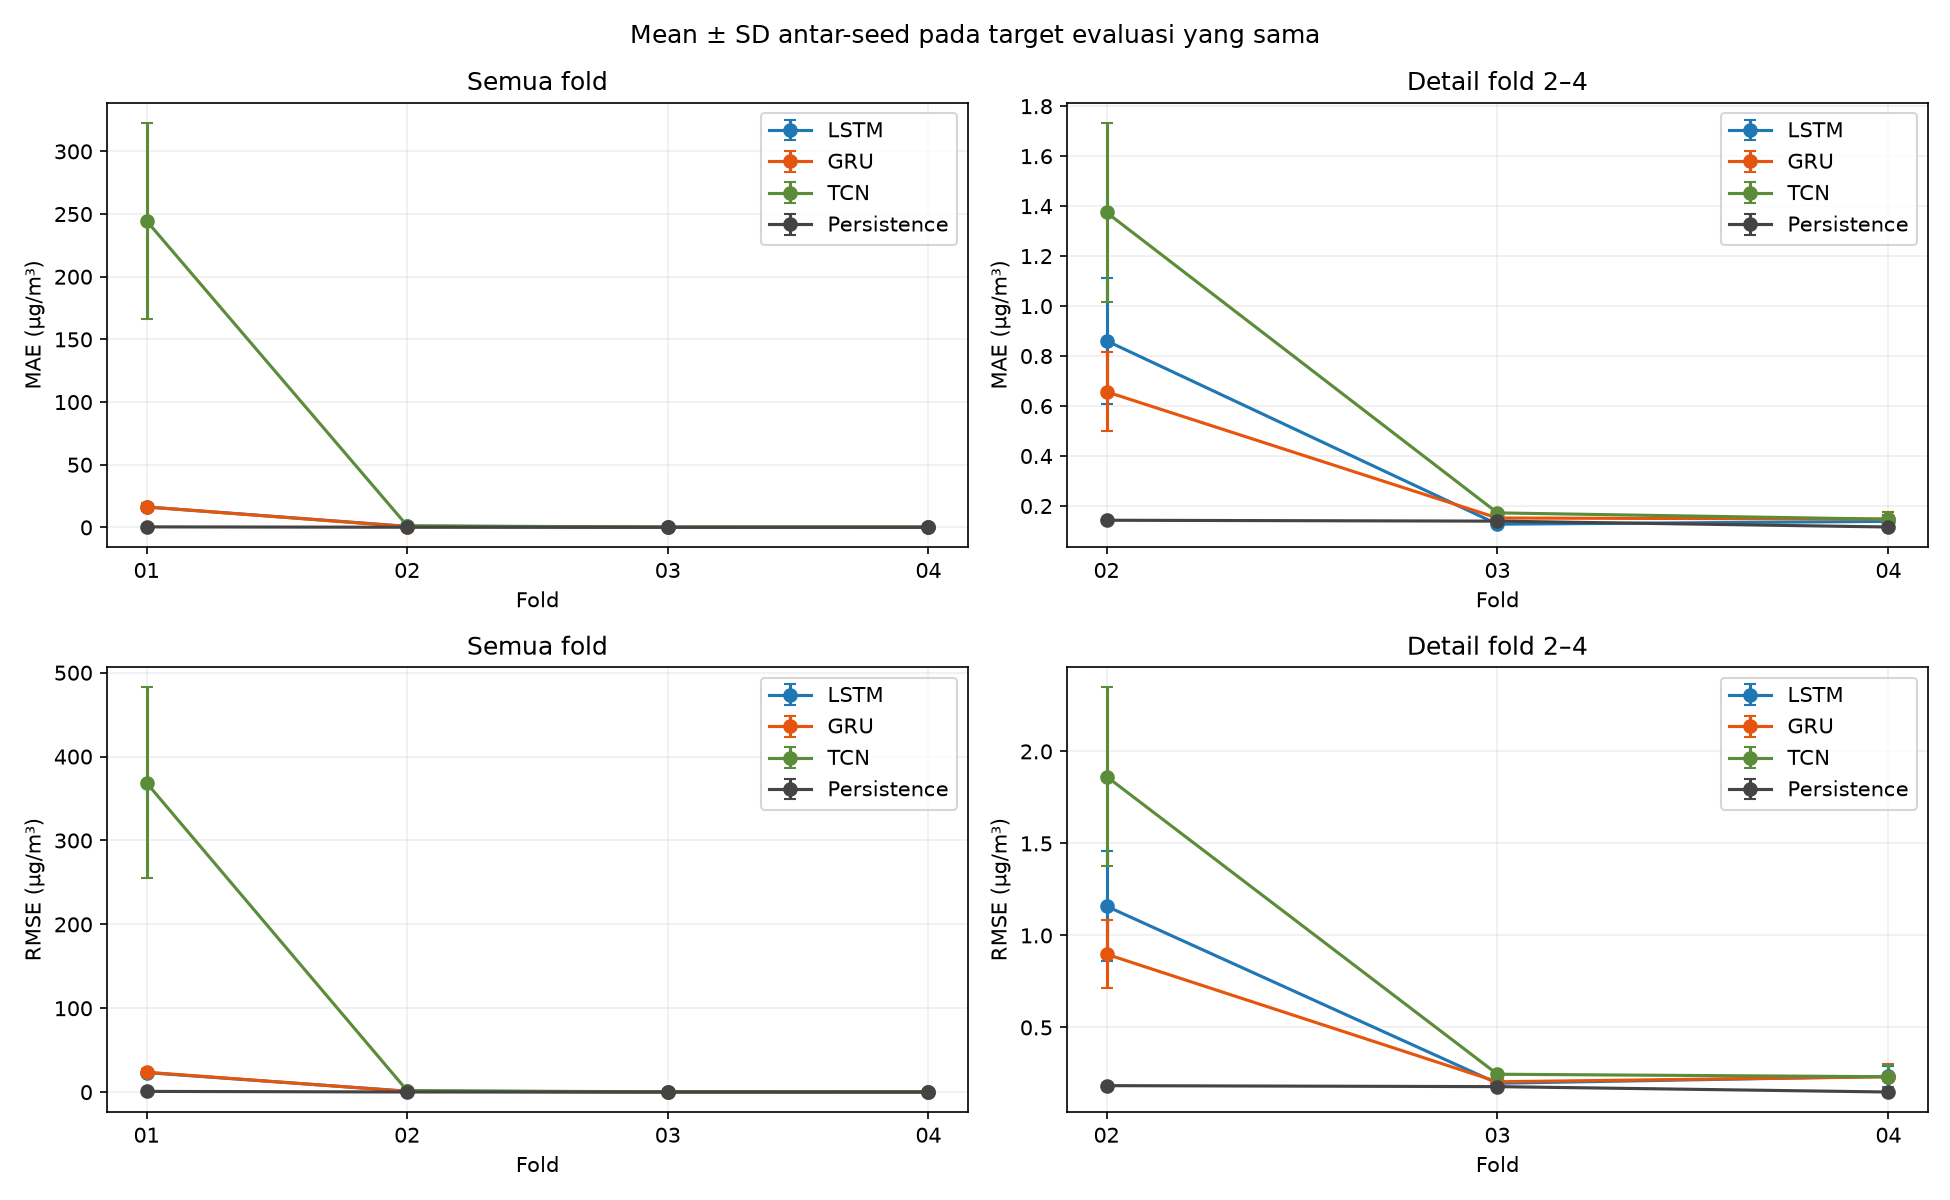

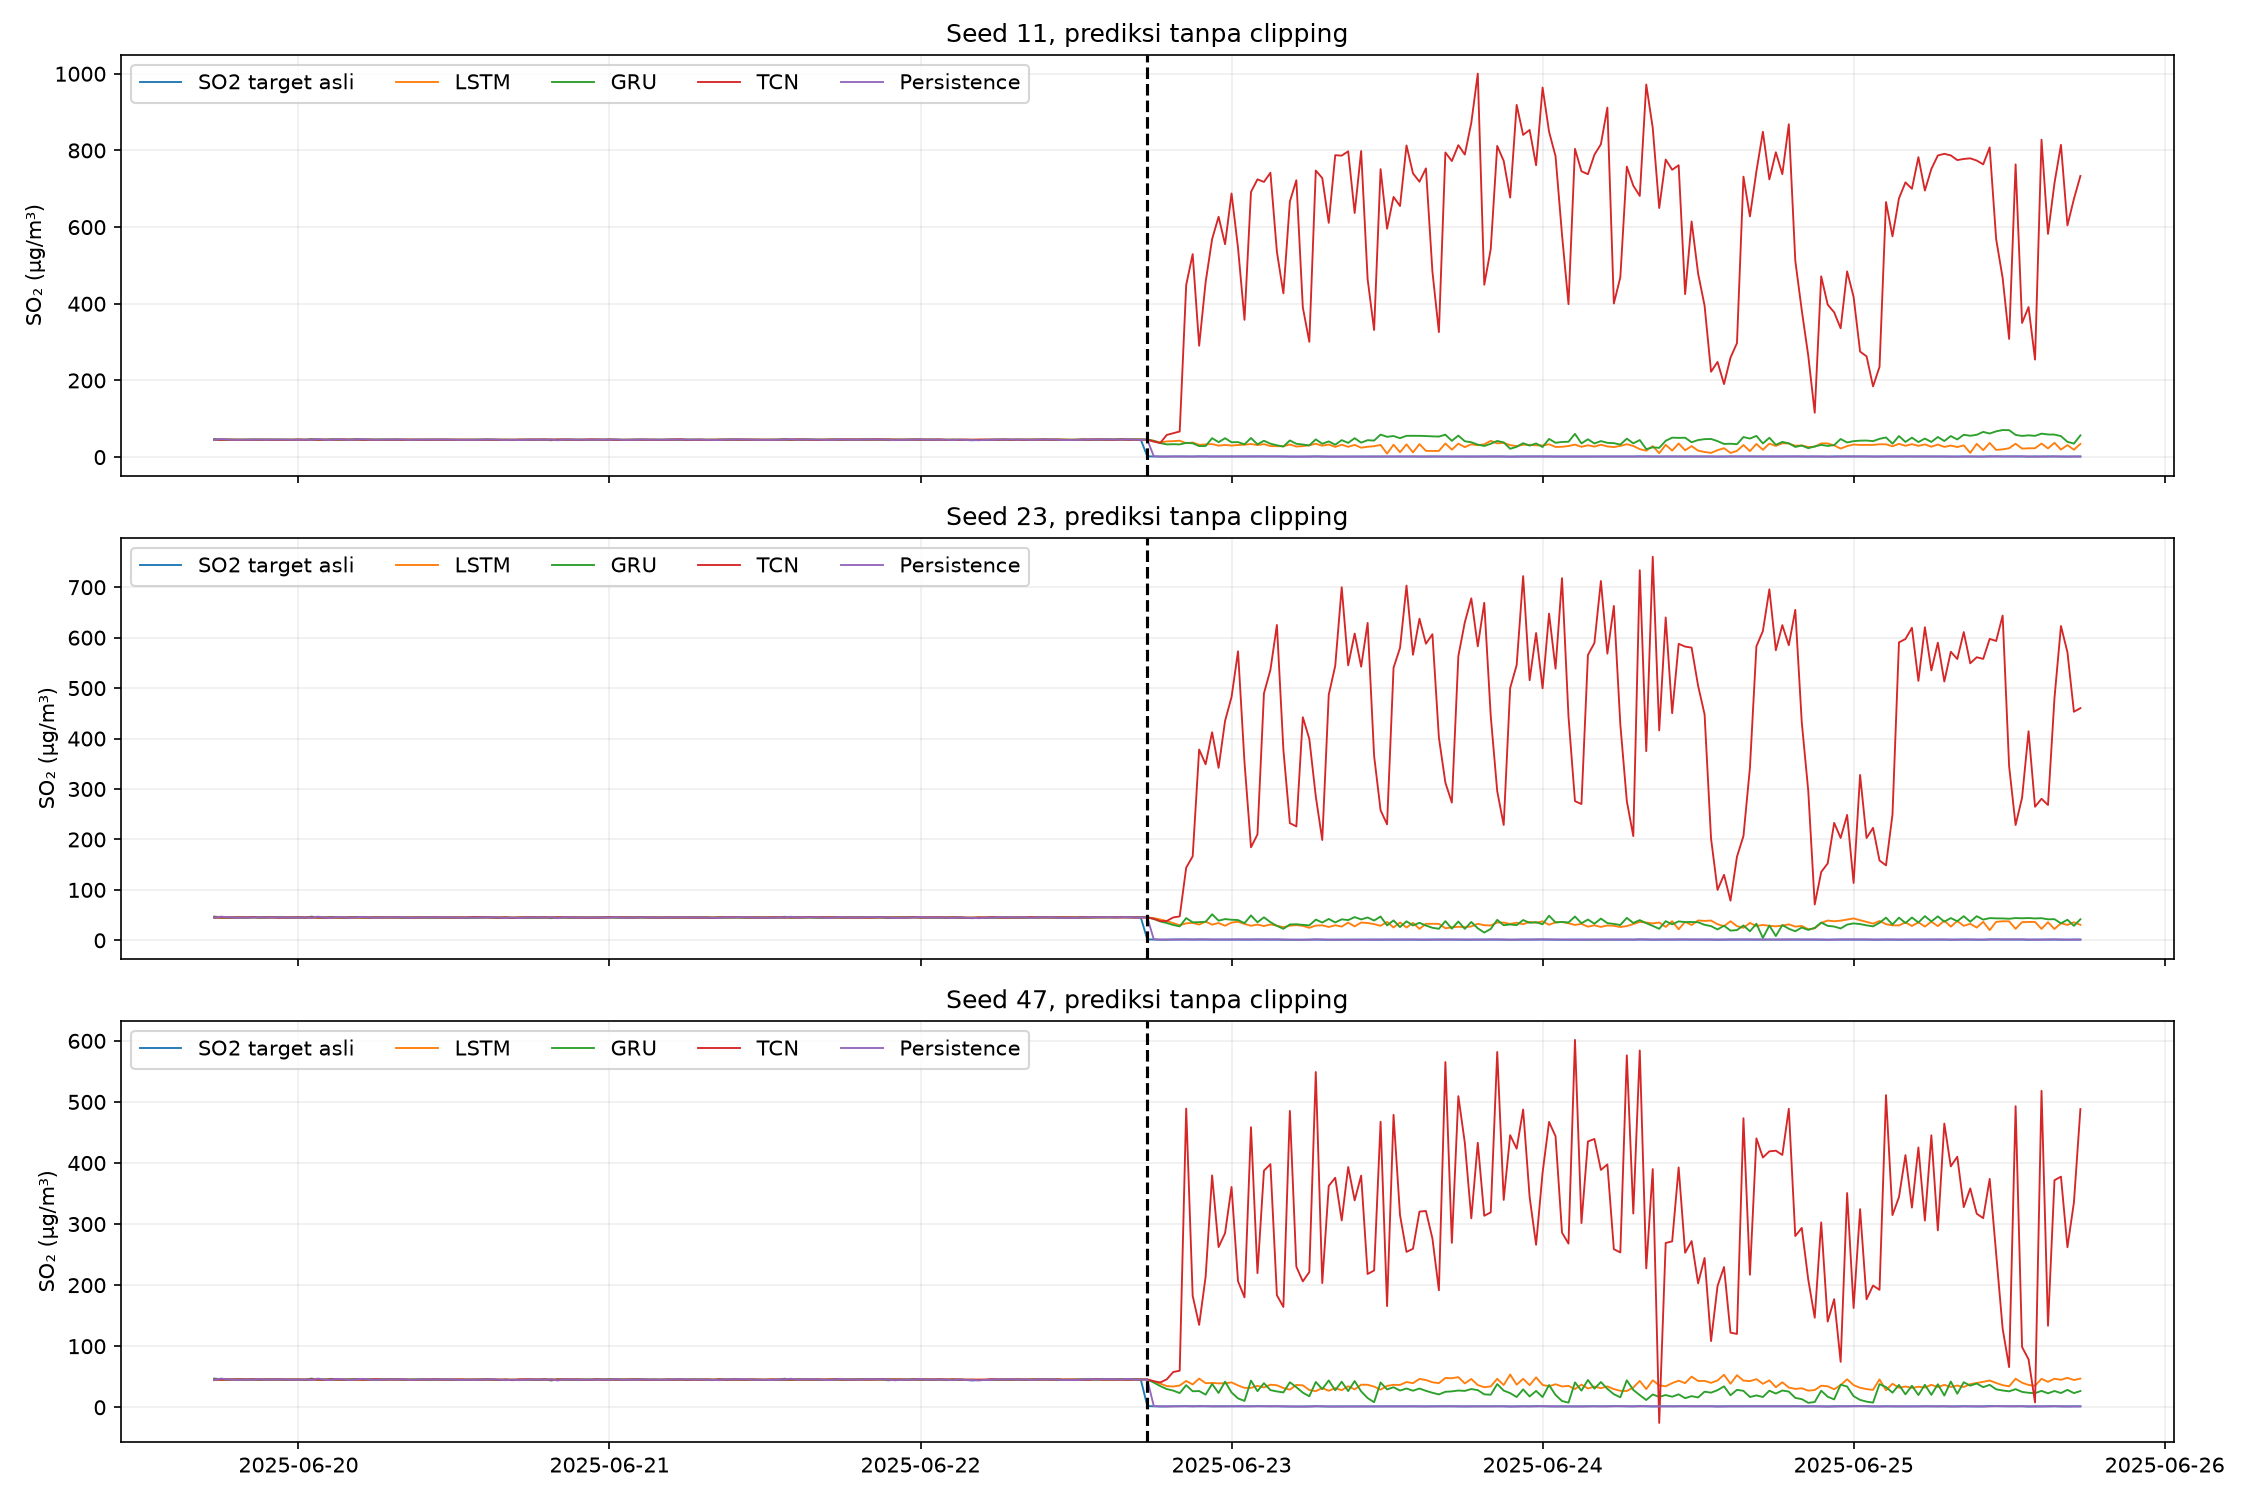

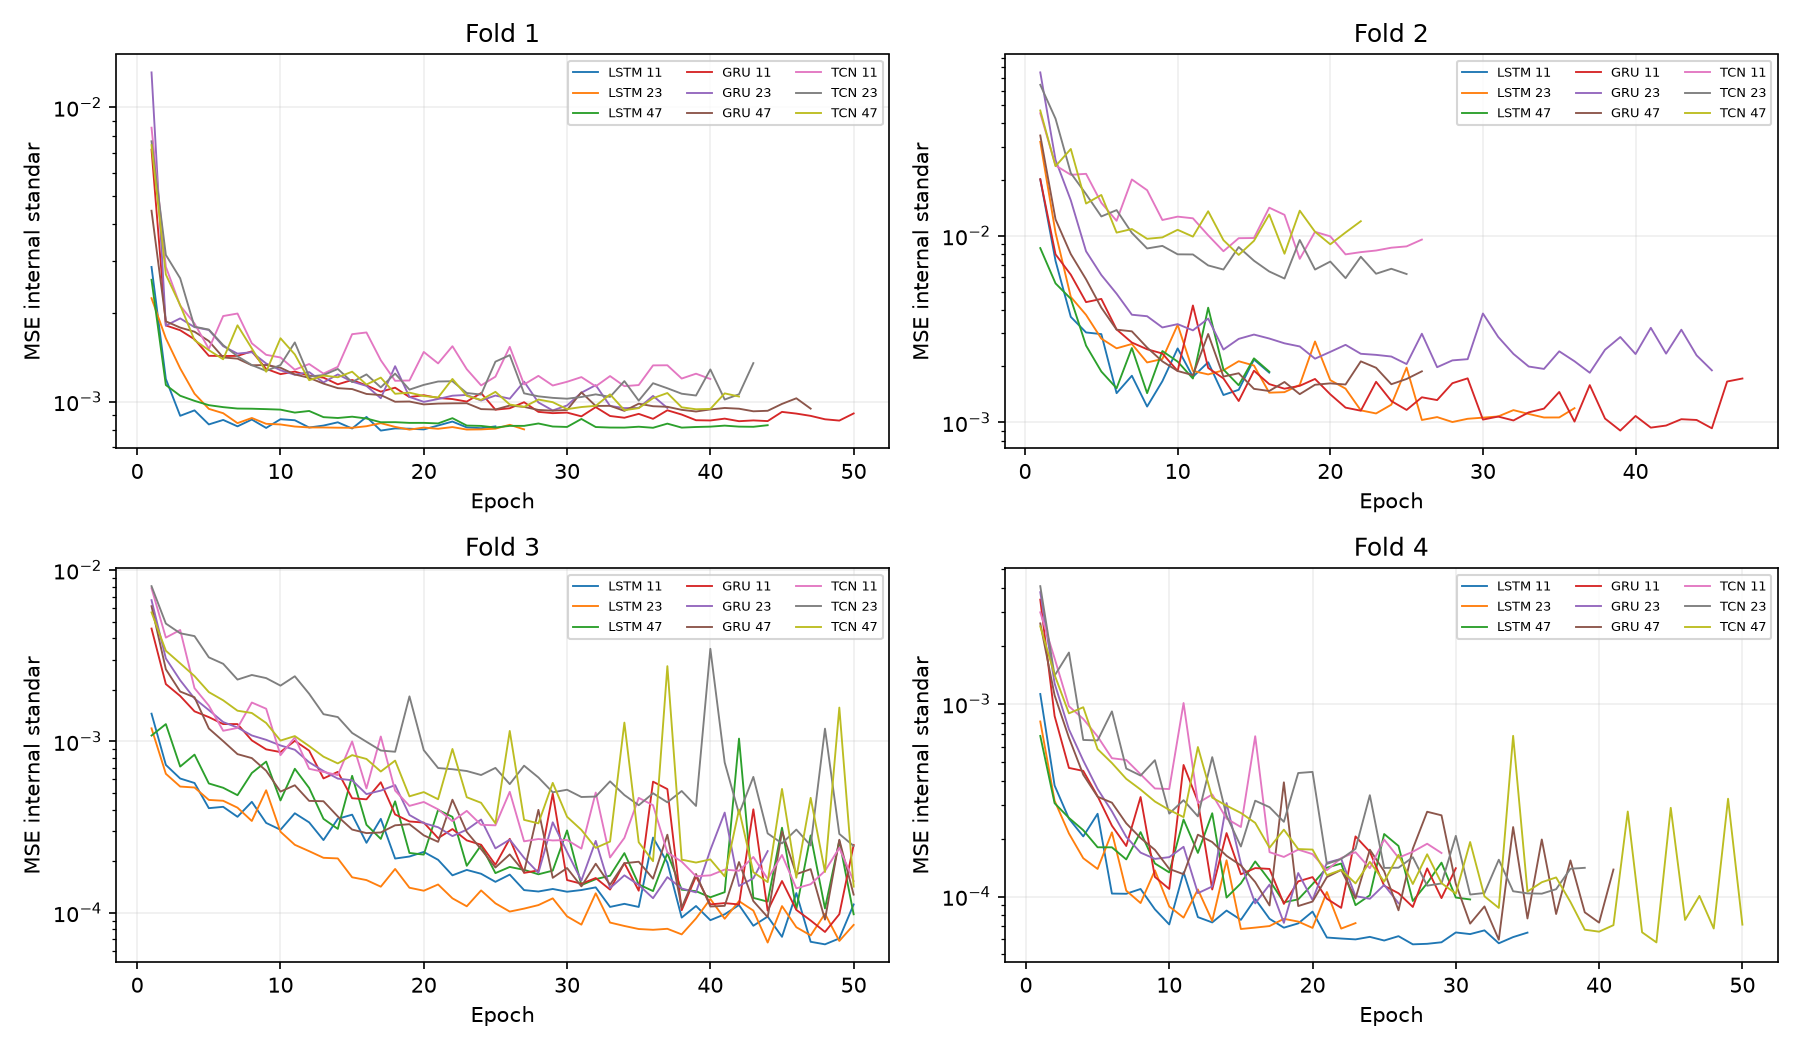

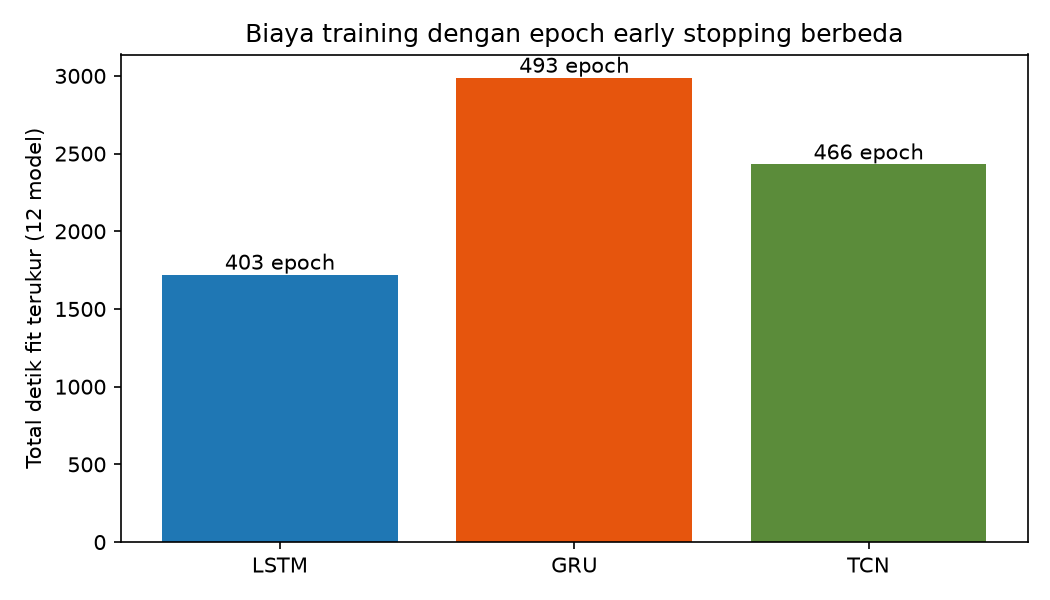

In [4]:
for name in ['skor_per_fold.png','transisi_22_juni.png','riwayat_internal.png','waktu_training.png']:
    display(Image(filename=str(RUN/'figures'/name)))
print('Verifikasi tanpa fit:',json.loads((RUN/'independent_checks.json').read_text(encoding='utf-8')))


## Workbook, ringkasan dan status proyek

Ekspor Artifact Tool dilakukan dari tabel hasil yang sudah diperiksa. CSV menyimpan prediksi seluruh seed dan semua timestamp sampel. Checkpoint, riwayat dan waktu tiap model tersimpan dalam Fold_XX/GRU_seedXX atau TCN_seedXX.

In [5]:
node=Path(r'C:\Program Files\WindowsApps\OpenAI.CodexPrimaryRuntime.v26-1104-2876-0_26.1104.2876.0_x64__3k8sg7r9htsxt\dependencies\node\bin\node.exe')
result=subprocess.run([str(node),str(ROOT/'scripts/export_quality.mjs'),'perbandingan_algoritma_tahap11/tabel_hasil.json','perbandingan_algoritma_tahap11/hasil_perbandingan_algoritma.xlsx','perbandingan_algoritma_tahap11/previews'],cwd=ROOT,capture_output=True,text=True,encoding='utf-8')
print(result.stdout)
if result.returncode:raise RuntimeError(result.stderr)
display(Markdown((RUN/'ringkasan_perbandingan_algoritma.md').read_text(encoding='utf-8')))


{"kind":"table","sheet":"Ringkasan","address":"A1:F4","rows":4,"cols":6,"values":[["Fold","Algoritma","Domain","Seed N","MAE mean","MAE SD seed"],["Fold_01","LSTM","bersama",3,16.317958391502916,2.74457027234058],["Fold_01","GRU","bersama",3,16.339682248719466,3.239078603301616],["Fold_01","TCN","bersama",3,244.63982182869006,78.21093227779066]]}
Inspect result written to file: C:\Users\INTAN\airpollutan_SO2\outputs\perbandingan_algoritma_tahap11\hasil_perbandingan_algoritma.xlsx.inspect.ndjson
Ekspor selesai: 17 sheet.



# Tahap 11 — perbandingan algoritma SO₂ Way Urang

Eksperimen selesai dengan 24 model baru: GRU dan TCN masing-masing empat fold × tiga seed. Dua belas LSTM S0 tahap10 dipakai sebagai hasil acuan tersimpan, tanpa fit ulang. Target seluruh model adalah SO₂ Way Urang asli 30 menit setelah origin. Empat fold kalender, 15% akhir train sebagai validasi internal, warmup median30 hari, kanal Way Urang tanpa Curah Hujan, indikator missing dan sekuens48 slot identik. Development set telah digunakan sebelumnya; ini validasi pengembangan. Test akhir mulai 2026-06-19 06:30:00 tidak dimuat nilainya atau dievaluasi.

## Protokol terkunci sebelum training

Konfigurasi dikunci sebelum fit baru dengan SHA256 63b680d82cb7cf753824f2532ba9ce76d1695a415530790b23724c00467b54b0. Gate semua fold dan uji kausalitas TCN selesai saat jumlah fit baru=0. Input S0 langsung memakai tensor `.npz`, timestamp train/internal/evaluasi dan parameter scaler/target tahap10 yang diverifikasi. Tidak ada estimator imputasi atau scaler baru yang di-fit. Median kausal statistik hanya berasal dari prefix train internal tahap10; target asli tidak diimputasi.

| Fold | Train N | Internal N | Evaluasi N | Fitur kanal | Fitur terverifikasi | Scaler train internal | Fit baru sebelum gate | Lulus |
|---|---|---|---|---|---|---|---|---|
| Fold_01 | 2679 | 860 | 4890 | 22 | True | True | 0 | True |
| Fold_02 | 6822 | 1607 | 4969 | 22 | True | True | 0 | True |
| Fold_03 | 11042 | 2356 | 4969 | 22 | True | True | 0 | True |
| Fold_04 | 15267 | 3100 | 4969 | 22 | True | True | 0 | True |

| Fold | Bagian | Awal target | Akhir target | N | Minimum | P25 | Median | P75 | Maksimum | Mean | SD |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Fold_01 | inner_train | 2025-02-13 19:00:00 | 2025-04-12 23:30:00 | 2679 | 1.24 | 1.45 | 45.15 | 45.80 | 80.71 | 36.23 | 22.40 |
| Fold_01 | inner_validation | 2025-04-13 00:00:00 | 2025-04-30 23:30:00 | 860 | 43.72 | 45.02 | 45.45 | 45.84 | 47.29 | 45.44 | 0.62 |
| Fold_01 | evaluation | 2025-05-01 00:00:00 | 2025-08-12 13:30:00 | 4890 | 1.07 | 1.56 | 43.85 | 45.38 | 47.81 | 23.58 | 21.93 |
| Fold_02 | inner_train | 2025-02-13 19:00:00 | 2025-07-10 00:30:00 | 6822 | 1.07 | 44.24 | 45.18 | 45.74 | 80.71 | 36.49 | 19.59 |
| Fold_02 | inner_validation | 2025-07-10 01:00:00 | 2025-08-12 13:30:00 | 1607 | 1.08 | 1.49 | 1.56 | 1.63 | 2.10 | 1.56 | 0.12 |
| Fold_02 | evaluation | 2025-08-12 14:00:00 | 2025-11-24 03:00:00 | 4969 | 1.04 | 1.48 | 1.56 | 1.64 | 2.14 | 1.56 | 0.13 |
| Fold_03 | inner_train | 2025-02-13 19:00:00 | 2025-10-06 01:00:00 | 11042 | 1.04 | 1.54 | 1.76 | 45.39 | 80.71 | 23.14 | 22.92 |
| Fold_03 | inner_validation | 2025-10-06 01:30:00 | 2025-11-24 03:00:00 | 2356 | 1.04 | 1.47 | 1.56 | 1.65 | 2.07 | 1.56 | 0.14 |
| Fold_03 | evaluation | 2025-11-24 03:30:00 | 2026-03-07 16:30:00 | 4969 | 1.08 | 1.49 | 1.56 | 1.63 | 2.04 | 1.56 | 0.13 |
| Fold_04 | inner_train | 2025-02-13 19:00:00 | 2026-01-02 01:30:00 | 15267 | 1.04 | 1.52 | 1.64 | 45.05 | 80.71 | 17.17 | 21.75 |
| Fold_04 | inner_validation | 2026-01-02 02:00:00 | 2026-03-07 16:30:00 | 3100 | 1.08 | 1.49 | 1.56 | 1.63 | 2.04 | 1.56 | 0.12 |
| Fold_04 | evaluation | 2026-03-07 17:00:00 | 2026-06-19 06:00:00 | 4969 | 1.09 | 1.49 | 1.56 | 1.63 | 2.06 | 1.56 | 0.11 |

Setiap sampel memiliki48 slot30 menit origin−47 hingga origin, tanpa kompresi waktu. Kanal numerik11 distandardisasi dari slot train internal tahap10; 11 indikator missing asli tetap0/1. Target distandardisasi memakai mean/SD populasi train internal yang sama untuk semua arsitektur, lalu prediksi di-inverse sebelum penilaian. Sampel yang targetnya melintasi batas antarbagian sudah dipurge pada tahap10 dan indeksnya cocok dengan tensor tersimpan. Target evaluasi kosong tidak dinilai. Nol, ekstrem dan rentetan konstan tidak dihapus berdasarkan besarnya.

GRU: satu layer unidirectional32 unit, Dense linear satu output. TCN: empat residual block16 kanal, tiapblock dua Conv1d kernel3 dengan dilation1/2/4/8, ReLU, dropout0 dan output linear dari langkah terakhir. Blok pertama memakai proyeksi skip1×1 dari22 ke16 kanal agar penjumlahan residual terdefinisi. Tiapconv melakukan padding2×dilation lalu memangkas bagian kanan sehingga keluaran waktu t hanya bergantung pada masukan≤t. Receptive field teoritis61 slot dibatasi jendela48 slot. Uji pemotongan prefix dan gangguan masa depan pada enam panjang prefix menunjukkan keluaran terdahulu tidak berubah.

| Algoritma | Model N | Jumlah parameter | Epoch total | Epoch median | Fit total detik | Fit median detik | Predict total detik |
|---|---|---|---|---|---|---|---|
| LSTM | 12 | 7201 | 403 | 33.00 | 1720.992834 | 145.731866 | 8.076428 |
| GRU | 12 | 5409 | 493 | 44.50 | 2988.276425 | 256.406870 | 5.601153 |
| TCN | 12 | 6945 | 466 | 41.00 | 2430.616222 | 147.746839 | 9.530204 |

Semua model baru memakai Adam learning rate0,001, MSE target standar, batch64, maksimal50 epoch, early stopping patience8, bobot terbaik internal dipulihkan. Seed11/23/47 ditetapkan sebelum fit. Anggaran ini sama, tetapi jumlah parameter, biaya per-epoch, epoch terbaik dan tingkat optimisasi tidak otomatis sama. TCN memiliki receptive field lebih panjang dari jendela input tanpa membaca setelah origin. Tidak ada clipping atau pemilihan seed terbaik.

## Hasil pada timestamp yang identik

| Fold | Seed | Algoritma | N | Denominator target asli | Cakupan persen | MAE | RMSE | Bias | Prediksi negatif |
|---|---|---|---|---|---|---|---|---|---|
| Fold_01 | 11 | LSTM | 4890 | 4890 | 100.000 | 14.088429 | 20.431628 | 13.834207 | 0 |
| Fold_01 | 11 | GRU | 4890 | 4890 | 100.000 | 19.609663 | 28.138338 | 19.351973 | 0 |
| Fold_01 | 11 | TCN | 4890 | 4890 | 100.000 | 328.367711 | 489.640110 | 328.118681 | 0 |
| Fold_01 | 11 | Persistence | 4890 | 4890 | 100.000 | 0.430562 | 0.885256 | 0.009049 | 0 |
| Fold_01 | 23 | LSTM | 4890 | 4890 | 100.000 | 15.482194 | 21.866398 | 15.211474 | 0 |
| Fold_01 | 23 | GRU | 4890 | 4890 | 100.000 | 16.276966 | 23.628969 | 15.983170 | 0 |
| Fold_01 | 23 | TCN | 4890 | 4890 | 100.000 | 232.087657 | 352.544512 | 231.807338 | 0 |
| Fold_01 | 23 | Persistence | 4890 | 4890 | 100.000 | 0.430562 | 0.885256 | 0.009049 | 0 |
| Fold_01 | 47 | LSTM | 4890 | 4890 | 100.000 | 19.383252 | 27.573651 | 19.127404 | 0 |
| Fold_01 | 47 | GRU | 4890 | 4890 | 100.000 | 13.132417 | 19.420564 | 12.872023 | 1 |
| Fold_01 | 47 | TCN | 4890 | 4890 | 100.000 | 173.464098 | 264.084674 | 173.026827 | 13 |
| Fold_01 | 47 | Persistence | 4890 | 4890 | 100.000 | 0.430562 | 0.885256 | 0.009049 | 0 |
| Fold_02 | 11 | LSTM | 4969 | 4969 | 100.000 | 0.734822 | 1.073573 | 0.377596 | 22 |
| Fold_02 | 11 | GRU | 4969 | 4969 | 100.000 | 0.488065 | 0.693082 | 0.106261 | 41 |
| Fold_02 | 11 | TCN | 4969 | 4969 | 100.000 | 1.500571 | 2.114207 | 0.895538 | 306 |
| Fold_02 | 11 | Persistence | 4969 | 4969 | 100.000 | 0.142954 | 0.183682 | -0.000020 | 0 |
| Fold_02 | 23 | LSTM | 4969 | 4969 | 100.000 | 1.152306 | 1.490542 | 0.971297 | 55 |
| Fold_02 | 23 | GRU | 4969 | 4969 | 100.000 | 0.681395 | 0.946404 | 0.375669 | 46 |
| Fold_02 | 23 | TCN | 4969 | 4969 | 100.000 | 0.970077 | 1.305899 | 0.050065 | 488 |
| Fold_02 | 23 | Persistence | 4969 | 4969 | 100.000 | 0.142954 | 0.183682 | -0.000020 | 0 |
| Fold_02 | 47 | LSTM | 4969 | 4969 | 100.000 | 0.696230 | 0.911808 | 0.229197 | 90 |
| Fold_02 | 47 | GRU | 4969 | 4969 | 100.000 | 0.801896 | 1.054446 | -0.466425 | 572 |
| Fold_02 | 47 | TCN | 4969 | 4969 | 100.000 | 1.654132 | 2.170650 | -0.987216 | 1797 |
| Fold_02 | 47 | Persistence | 4969 | 4969 | 100.000 | 0.142954 | 0.183682 | -0.000020 | 0 |
| Fold_03 | 11 | LSTM | 4969 | 4969 | 100.000 | 0.121554 | 0.167534 | -0.018705 | 2 |
| Fold_03 | 11 | GRU | 4969 | 4969 | 100.000 | 0.133314 | 0.180168 | -0.028826 | 0 |
| Fold_03 | 11 | TCN | 4969 | 4969 | 100.000 | 0.162770 | 0.250036 | 0.043927 | 4 |
| Fold_03 | 11 | Persistence | 4969 | 4969 | 100.000 | 0.139453 | 0.178418 | 0.000016 | 0 |
| Fold_03 | 23 | LSTM | 4969 | 4969 | 100.000 | 0.125210 | 0.192803 | -0.011169 | 2 |
| Fold_03 | 23 | GRU | 4969 | 4969 | 100.000 | 0.183474 | 0.251445 | 0.073051 | 5 |
| Fold_03 | 23 | TCN | 4969 | 4969 | 100.000 | 0.181203 | 0.252752 | 0.095959 | 4 |
| Fold_03 | 23 | Persistence | 4969 | 4969 | 100.000 | 0.139453 | 0.178418 | 0.000016 | 0 |
| Fold_03 | 47 | LSTM | 4969 | 4969 | 100.000 | 0.134902 | 0.229740 | 0.019808 | 5 |
| Fold_03 | 47 | GRU | 4969 | 4969 | 100.000 | 0.139163 | 0.182469 | 0.047691 | 0 |
| Fold_03 | 47 | TCN | 4969 | 4969 | 100.000 | 0.173463 | 0.234342 | -0.037517 | 2 |
| Fold_03 | 47 | Persistence | 4969 | 4969 | 100.000 | 0.139453 | 0.178418 | 0.000016 | 0 |
| Fold_04 | 11 | LSTM | 4969 | 4969 | 100.000 | 0.112114 | 0.167962 | 0.017715 | 2 |
| Fold_04 | 11 | GRU | 4969 | 4969 | 100.000 | 0.119874 | 0.168396 | 0.026207 | 0 |
| Fold_04 | 11 | TCN | 4969 | 4969 | 100.000 | 0.175576 | 0.281948 | -0.032021 | 1 |
| Fold_04 | 11 | Persistence | 4969 | 4969 | 100.000 | 0.115935 | 0.149092 | 0.000024 | 0 |
| Fold_04 | 23 | LSTM | 4969 | 4969 | 100.000 | 0.145639 | 0.270735 | -0.005944 | 3 |
| Fold_04 | 23 | GRU | 4969 | 4969 | 100.000 | 0.179352 | 0.305018 | 0.046352 | 0 |
| Fold_04 | 23 | TCN | 4969 | 4969 | 100.000 | 0.148633 | 0.255667 | -0.052439 | 6 |
| Fold_04 | 23 | Persistence | 4969 | 4969 | 100.000 | 0.115935 | 0.149092 | 0.000024 | 0 |
| Fold_04 | 47 | LSTM | 4969 | 4969 | 100.000 | 0.157629 | 0.263519 | 0.079551 | 10 |
| Fold_04 | 47 | GRU | 4969 | 4969 | 100.000 | 0.143443 | 0.222042 | 0.099806 | 0 |
| Fold_04 | 47 | TCN | 4969 | 4969 | 100.000 | 0.116785 | 0.158830 | 0.010701 | 2 |
| Fold_04 | 47 | Persistence | 4969 | 4969 | 100.000 | 0.115935 | 0.149092 | 0.000024 | 0 |

Error e=prediksi−target asli; MAE=mean(|e|), RMSE=sqrt(mean(e²)), bias=mean(e), seluruhnya µg/m³. Cakupan=100×N prediksi finite / seluruh target Way Urang numerik asli teramati pada jendela fold. Skor bersama memakai irisan timestamp LSTM/GRU/TCN/persistence; digest timestamp disimpan dalam workbook. Workbook juga memuat domain mandiri sehingga kemungkinan kegagalan prediksi tidak tersembunyi oleh irisan. Persistence memakai pengamatan SO₂ Way Urang asli terakhir pada/sebelum origin, tanpa imputasi atau batas usia.

| Fold | Algoritma | MAE mean | MAE SD seed | RMSE mean | RMSE SD seed | Bias mean | Bias SD seed | Cakupan persen mean | Prediksi negatif mean |
|---|---|---|---|---|---|---|---|---|---|
| Fold_01 | LSTM | 16.317958 | 2.744570 | 23.290559 | 3.778002 | 16.057695 | 2.746188 | 100.000 | 0.00 |
| Fold_01 | GRU | 16.339682 | 3.239079 | 23.729290 | 4.359752 | 16.069055 | 3.240829 | 100.000 | 0.33 |
| Fold_01 | TCN | 244.639822 | 78.210932 | 368.756432 | 113.648288 | 244.317615 | 78.299113 | 100.000 | 4.33 |
| Fold_01 | Persistence | 0.430562 | 0.000000 | 0.885256 | 0.000000 | 0.009049 | 0.000000 | 100.000 | 0.00 |
| Fold_02 | LSTM | 0.861119 | 0.252912 | 1.158641 | 0.298598 | 0.526030 | 0.392686 | 100.000 | 55.67 |
| Fold_02 | GRU | 0.657119 | 0.158318 | 0.897977 | 0.185486 | 0.005168 | 0.430053 | 100.000 | 219.67 |
| Fold_02 | TCN | 1.374927 | 0.358919 | 1.863585 | 0.483795 | -0.013871 | 0.943004 | 100.000 | 863.67 |
| Fold_02 | Persistence | 0.142954 | 0.000000 | 0.183682 | 0.000000 | -0.000020 | 0.000000 | 100.000 | 0.00 |
| Fold_03 | LSTM | 0.127222 | 0.006898 | 0.196692 | 0.031285 | -0.003355 | 0.020411 | 100.000 | 3.00 |
| Fold_03 | GRU | 0.151984 | 0.027428 | 0.204694 | 0.040504 | 0.030639 | 0.053036 | 100.000 | 1.67 |
| Fold_03 | TCN | 0.172479 | 0.009256 | 0.245710 | 0.009938 | 0.034123 | 0.067276 | 100.000 | 3.33 |
| Fold_03 | Persistence | 0.139453 | 0.000000 | 0.178418 | 0.000000 | 0.000016 | 0.000000 | 100.000 | 0.00 |
| Fold_04 | LSTM | 0.138461 | 0.023591 | 0.234072 | 0.057367 | 0.030441 | 0.044145 | 100.000 | 5.00 |
| Fold_04 | GRU | 0.147556 | 0.029952 | 0.231819 | 0.068834 | 0.057455 | 0.038035 | 100.000 | 0.00 |
| Fold_04 | TCN | 0.146998 | 0.029429 | 0.232149 | 0.064841 | -0.024586 | 0.032220 | 100.000 | 3.00 |
| Fold_04 | Persistence | 0.115935 | 0.000000 | 0.149092 | 0.000000 | 0.000024 | 0.000000 | 100.000 | 0.00 |

Rata-rata dan SD sampel (ddof1) memakai tiga seed tetap. Persistence deterministik diulang dalam tabel seed hanya agar semua pembandingan memakai timestamp sama; pengulangannya bukan tiga replikasi independen. Tidak menarik kesimpulan signifikansi statistik dari SD atau selisih rerata.

## Gabungan fold dan perubahan terhadap persistence

| Seed | Algoritma | N | Cakupan persen | MAE | RMSE | Bias | Prediksi negatif |
|---|---|---|---|---|---|---|---|
| 11 | LSTM | 19797 | 100.000 | 3.723031 | 10.169410 | 3.511675 | 26 |
| 11 | GRU | 19797 | 100.000 | 5.029779 | 13.989556 | 4.806089 | 41 |
| 11 | TCN | 19797 | 100.000 | 81.570727 | 243.352588 | 81.275417 | 311 |
| 11 | Persistence | 19797 | 100.000 | 0.206335 | 0.464340 | 0.002240 | 0 |
| 23 | LSTM | 19797 | 100.000 | 4.181421 | 10.894457 | 3.996841 | 60 |
| 23 | GRU | 19797 | 100.000 | 4.282624 | 11.754789 | 4.072219 | 51 |
| 23 | TCN | 19797 | 100.000 | 57.653579 | 175.215271 | 57.281553 | 498 |
| 23 | Persistence | 19797 | 100.000 | 0.206335 | 0.464340 | 0.002240 | 0 |
| 47 | LSTM | 19797 | 100.000 | 5.035978 | 13.712783 | 4.807072 | 105 |
| 47 | GRU | 19797 | 100.000 | 3.516008 | 9.667502 | 3.099431 | 573 |
| 47 | TCN | 19797 | 100.000 | 43.334903 | 131.254166 | 42.484339 | 1814 |
| 47 | Persistence | 19797 | 100.000 | 0.206335 | 0.464340 | 0.002240 | 0 |

Gabungan dihitung dari seluruh error evaluasi fold yang tidak tumpang tindih per seed; RMSE gabungan tidak dirata-ratakan dari RMSE fold.

| Algoritma | MAE mean | MAE SD seed | RMSE mean | RMSE SD seed | Bias mean | Cakupan persen mean | Prediksi negatif mean |
|---|---|---|---|---|---|---|---|
| LSTM | 4.313477 | 0.666361 | 11.592217 | 1.871904 | 4.105196 | 100.000 | 63.67 |
| GRU | 4.276137 | 0.756906 | 11.803949 | 2.161446 | 3.992580 | 100.000 | 221.67 |
| TCN | 60.853070 | 19.317663 | 183.274008 | 56.482046 | 60.347103 | 100.000 | 874.33 |
| Persistence | 0.206335 | 0.000000 | 0.464340 | 0.000000 | 0.002240 | 100.000 | 0.00 |

| Algoritma | MAE lebih rendah dari persistence N/12 | RMSE lebih rendah dari persistence N/12 | Kedua metrik lebih rendah dari persistence N/12 | Mengungguli dua DL lain pada kedua metrik N/12 |
|---|---|---|---|---|
| LSTM | 4 | 1 | 1 | 6 |
| GRU | 2 | 0 | 0 | 3 |
| TCN | 0 | 0 | 0 | 1 |

| Fold | Seed | Algoritma | N identik | Delta MAE vs persistence | Delta RMSE vs persistence | Perbaikan MAE persen | Perbaikan RMSE persen |
|---|---|---|---|---|---|---|---|
| Fold_01 | 11 | LSTM | 4890 | 13.657867 | 19.546372 | -3172.099423 | -2207.991490 |
| Fold_01 | 11 | GRU | 4890 | 19.179101 | 27.253082 | -4454.430370 | -3078.554512 |
| Fold_01 | 11 | TCN | 4890 | 327.937148 | 488.754854 | -76164.841471 | -55210.579817 |
| Fold_01 | 23 | LSTM | 4890 | 15.051631 | 20.981143 | -3495.807439 | -2370.065552 |
| Fold_01 | 23 | GRU | 4890 | 15.846404 | 22.743713 | -3680.396829 | -2569.168545 |
| Fold_01 | 23 | TCN | 4890 | 231.657094 | 351.659256 | -53803.376569 | -39724.027874 |
| Fold_01 | 47 | LSTM | 4890 | 18.952690 | 26.688395 | -4401.845428 | -3014.766556 |
| Fold_01 | 47 | GRU | 4890 | 12.701855 | 18.535309 | -2950.061475 | -2093.780005 |
| Fold_01 | 47 | TCN | 4890 | 173.033536 | 263.199418 | -40187.797834 | -29731.454040 |
| Fold_02 | 11 | LSTM | 4969 | 0.591868 | 0.889892 | -414.026064 | -484.475054 |
| Fold_02 | 11 | GRU | 4969 | 0.345111 | 0.509400 | -241.413384 | -277.327647 |
| Fold_02 | 11 | TCN | 4969 | 1.357617 | 1.930526 | -949.685600 | -1051.017226 |
| Fold_02 | 23 | LSTM | 4969 | 1.009352 | 1.306861 | -706.065967 | -711.481423 |
| Fold_02 | 23 | GRU | 4969 | 0.538441 | 0.762722 | -376.652240 | -415.241306 |
| Fold_02 | 23 | TCN | 4969 | 0.827123 | 1.122217 | -578.592567 | -610.957644 |
| Fold_02 | 47 | LSTM | 4969 | 0.553276 | 0.728127 | -387.029593 | -396.406863 |
| Fold_02 | 47 | GRU | 4969 | 0.658942 | 0.870764 | -460.945901 | -474.061782 |
| Fold_02 | 47 | TCN | 4969 | 1.511178 | 1.986968 | -1057.105565 | -1081.745724 |
| Fold_03 | 11 | LSTM | 4969 | -0.017899 | -0.010884 | 12.834968 | 6.100307 |
| Fold_03 | 11 | GRU | 4969 | -0.006139 | 0.001750 | 4.402084 | -0.980924 |
| Fold_03 | 11 | TCN | 4969 | 0.023317 | 0.071618 | -16.720398 | -40.140879 |
| Fold_03 | 23 | LSTM | 4969 | -0.014243 | 0.014385 | 10.213391 | -8.062449 |
| Fold_03 | 23 | GRU | 4969 | 0.044021 | 0.073027 | -31.567344 | -40.930301 |
| Fold_03 | 23 | TCN | 4969 | 0.041750 | 0.074334 | -29.938695 | -41.663128 |
| Fold_03 | 47 | LSTM | 4969 | -0.004551 | 0.051322 | 3.263280 | -28.765306 |
| Fold_03 | 47 | GRU | 4969 | -0.000289 | 0.004051 | 0.207595 | -2.270620 |
| Fold_03 | 47 | TCN | 4969 | 0.034011 | 0.055924 | -24.388614 | -31.344429 |
| Fold_04 | 11 | LSTM | 4969 | -0.003821 | 0.018870 | 3.295520 | -12.656645 |
| Fold_04 | 11 | GRU | 4969 | 0.003939 | 0.019305 | -3.397440 | -12.948134 |
| Fold_04 | 11 | TCN | 4969 | 0.059641 | 0.132857 | -51.443737 | -89.110514 |
| Fold_04 | 23 | LSTM | 4969 | 0.029704 | 0.121643 | -25.621296 | -81.589352 |
| Fold_04 | 23 | GRU | 4969 | 0.063418 | 0.155927 | -54.701089 | -104.584202 |
| Fold_04 | 23 | TCN | 4969 | 0.032698 | 0.106576 | -28.203649 | -71.483179 |
| Fold_04 | 47 | LSTM | 4969 | 0.041694 | 0.114427 | -35.963264 | -76.749617 |
| Fold_04 | 47 | GRU | 4969 | 0.027508 | 0.072950 | -23.727214 | -48.929482 |
| Fold_04 | 47 | TCN | 4969 | 0.000851 | 0.009738 | -0.733643 | -6.531804 |
| Gabungan_OOF | 11 | LSTM | 19797 | 3.516696 | 9.705070 | -1704.364134 | -2090.078280 |
| Gabungan_OOF | 11 | GRU | 19797 | 4.823444 | 13.525216 | -2337.678576 | -2912.782919 |
| Gabungan_OOF | 11 | TCN | 19797 | 81.364392 | 242.888248 | -39433.189569 | -52308.274907 |
| Gabungan_OOF | 23 | LSTM | 19797 | 3.975086 | 10.430117 | -1926.522243 | -2246.224169 |
| Gabungan_OOF | 23 | GRU | 19797 | 4.076289 | 11.290449 | -1975.570255 | -2431.504735 |
| Gabungan_OOF | 23 | TCN | 19797 | 57.447244 | 174.750931 | -27841.762510 | -37634.261003 |
| Gabungan_OOF | 47 | LSTM | 19797 | 4.829643 | 13.248443 | -2340.682802 | -2853.177108 |
| Gabungan_OOF | 47 | GRU | 19797 | 3.309673 | 9.203162 | -1604.030583 | -1981.987761 |
| Gabungan_OOF | 47 | TCN | 19797 | 43.128568 | 130.789826 | -20902.226982 | -28166.822487 |

Delta=error model−error persistence; negatif berarti model lebih baik. Perbaikan persen=100×(error persistence−error model)/error persistence, sehingga positif berarti error lebih rendah. Semua selisih dihitung pada target asli dan timestamp yang sama. Hasil bulanan, perubahan bulanan, dan distribusi target tiap bulan ada dalam workbook; bulan yang memotong batas fold dipisahkan menurut fold.

![Skor per fold](figures/skor_per_fold.png)

## Transisi 22 Juni 2025

Tanggal pusat 2025-06-22 17:30 mengikuti diagnosis sebelumnya; jendela ±72 jam dan fold pertama dipertahankan tanpa memilihnya berdasarkan skor tahap11. Grafik menampilkan target asli, ketiga arsitektur dan persistence untuk semua seed tanpa clipping.

| Algoritma | Target mean | Prediksi mean minimum antar-seed | Prediksi mean maksimum antar-seed | MAE mean antar-seed | RMSE mean antar-seed |
|---|---|---|---|---|---|
| LSTM | 1.56 | 28.69 | 37.60 | 31.226380 | 31.865499 |
| GRU | 1.56 | 26.47 | 42.88 | 33.197201 | 34.526500 |
| TCN | 1.56 | 305.65 | 599.48 | 442.656162 | 479.723308 |
| Persistence | 1.56 | 1.86 | 1.86 | 0.465034 | 3.600567 |

| Periode | Fold | Seed | Algoritma | N | MAE | RMSE | Bias | Prediksi negatif |
|---|---|---|---|---|---|---|---|---|
| sebelum | Fold_01 | 11 | LSTM | 144 | 0.442596 | 0.569922 | 0.049806 | 0 |
| sebelum | Fold_01 | 11 | GRU | 144 | 0.457069 | 0.585577 | 0.009639 | 0 |
| sebelum | Fold_01 | 11 | TCN | 144 | 0.454253 | 0.597226 | 0.078119 | 0 |
| sebelum | Fold_01 | 11 | Persistence | 144 | 0.602500 | 0.783946 | -0.005556 | 0 |
| sesudah | Fold_01 | 11 | LSTM | 145 | 27.132007 | 28.113190 | 27.132007 | 0 |
| sesudah | Fold_01 | 11 | GRU | 145 | 41.321611 | 42.668149 | 41.321611 | 0 |
| sesudah | Fold_01 | 11 | TCN | 145 | 597.923325 | 639.407427 | 597.923325 | 0 |
| sesudah | Fold_01 | 11 | Persistence | 145 | 0.465034 | 3.600567 | 0.301586 | 0 |
| sebelum | Fold_01 | 23 | LSTM | 144 | 0.465829 | 0.586869 | 0.039263 | 0 |
| sebelum | Fold_01 | 23 | GRU | 144 | 0.465164 | 0.598605 | -0.077800 | 0 |
| sebelum | Fold_01 | 23 | TCN | 144 | 0.475637 | 0.613553 | 0.049867 | 0 |
| sebelum | Fold_01 | 23 | Persistence | 144 | 0.602500 | 0.783946 | -0.005556 | 0 |
| sesudah | Fold_01 | 23 | LSTM | 145 | 30.509249 | 30.912249 | 30.509249 | 0 |
| sesudah | Fold_01 | 23 | GRU | 145 | 33.356095 | 34.393220 | 33.356095 | 0 |
| sesudah | Fold_01 | 23 | TCN | 145 | 425.582337 | 466.738289 | 425.582337 | 0 |
| sesudah | Fold_01 | 23 | Persistence | 145 | 0.465034 | 3.600567 | 0.301586 | 0 |
| sebelum | Fold_01 | 47 | LSTM | 144 | 0.439979 | 0.567788 | 0.012655 | 0 |
| sebelum | Fold_01 | 47 | GRU | 144 | 0.473765 | 0.602551 | -0.026787 | 0 |
| sebelum | Fold_01 | 47 | TCN | 144 | 0.465385 | 0.588474 | 0.041648 | 0 |
| sebelum | Fold_01 | 47 | Persistence | 144 | 0.602500 | 0.783946 | -0.005556 | 0 |
| sesudah | Fold_01 | 47 | LSTM | 145 | 36.037883 | 36.571058 | 36.037883 | 0 |
| sesudah | Fold_01 | 47 | GRU | 145 | 24.913898 | 26.518131 | 24.913898 | 0 |
| sesudah | Fold_01 | 47 | TCN | 145 | 304.462823 | 333.024208 | 304.086899 | 1 |
| sesudah | Fold_01 | 47 | Persistence | 145 | 0.465034 | 3.600567 | 0.301586 | 0 |

![Transisi](figures/transisi_22_juni.png)

## Biaya dan reproduksibilitas

| Fold | Algoritma | Seed | Sumber | Jumlah parameter | Epoch dijalankan | Epoch terbaik | Fit early stopping detik | Predict detik |
|---|---|---|---|---|---|---|---|---|
| Fold_01 | LSTM | 11 | checkpoint tahap10 S0 | 7201 | 25 | 17 | 30.123244 | 0.721320 |
| Fold_01 | GRU | 11 | fit baru tahap11 | 5409 | 50 | 42 | 91.005421 | 0.241116 |
| Fold_01 | TCN | 11 | fit baru tahap11 | 6945 | 40 | 32 | 73.733903 | 0.777790 |
| Fold_01 | LSTM | 23 | checkpoint tahap10 S0 | 7201 | 27 | 19 | 31.895839 | 0.789712 |
| Fold_01 | GRU | 23 | fit baru tahap11 | 5409 | 37 | 29 | 67.462608 | 0.474902 |
| Fold_01 | TCN | 23 | fit baru tahap11 | 6945 | 43 | 35 | 79.948146 | 0.925899 |
| Fold_01 | LSTM | 47 | checkpoint tahap10 S0 | 7201 | 44 | 36 | 51.430627 | 0.754926 |
| Fold_01 | GRU | 47 | fit baru tahap11 | 5409 | 47 | 39 | 98.470168 | 0.563847 |
| Fold_01 | TCN | 47 | fit baru tahap11 | 6945 | 42 | 34 | 74.336958 | 0.942287 |
| Fold_02 | LSTM | 11 | checkpoint tahap10 S0 | 7201 | 16 | 8 | 42.021976 | 0.162449 |
| Fold_02 | GRU | 11 | fit baru tahap11 | 5409 | 47 | 39 | 241.672046 | 0.460745 |
| Fold_02 | TCN | 11 | fit baru tahap11 | 6945 | 26 | 18 | 119.897668 | 0.829509 |
| Fold_02 | LSTM | 23 | checkpoint tahap10 S0 | 7201 | 36 | 28 | 108.757584 | 0.715620 |
| Fold_02 | GRU | 23 | fit baru tahap11 | 5409 | 45 | 37 | 226.240003 | 0.519746 |
| Fold_02 | TCN | 23 | fit baru tahap11 | 6945 | 25 | 17 | 115.458453 | 1.044720 |
| Fold_02 | LSTM | 47 | checkpoint tahap10 S0 | 7201 | 16 | 8 | 46.192421 | 0.671870 |
| Fold_02 | GRU | 47 | fit baru tahap11 | 5409 | 26 | 18 | 130.051118 | 0.465003 |
| Fold_02 | TCN | 47 | fit baru tahap11 | 6945 | 22 | 14 | 98.523552 | 0.891546 |
| Fold_03 | LSTM | 11 | checkpoint tahap10 S0 | 7201 | 50 | 48 | 241.332157 | 0.686639 |
| Fold_03 | GRU | 11 | fit baru tahap11 | 5409 | 50 | 48 | 402.820713 | 0.454102 |
| Fold_03 | TCN | 11 | fit baru tahap11 | 6945 | 50 | 46 | 361.092815 | 0.905308 |
| Fold_03 | LSTM | 23 | checkpoint tahap10 S0 | 7201 | 50 | 44 | 217.854205 | 0.236177 |
| Fold_03 | GRU | 23 | fit baru tahap11 | 5409 | 44 | 36 | 336.533871 | 0.420549 |
| Fold_03 | TCN | 23 | fit baru tahap11 | 6945 | 50 | 50 | 346.091458 | 0.799773 |
| Fold_03 | LSTM | 47 | checkpoint tahap10 S0 | 7201 | 50 | 50 | 238.204481 | 0.695024 |
| Fold_03 | GRU | 47 | fit baru tahap11 | 5409 | 50 | 48 | 381.245422 | 0.479126 |
| Fold_03 | TCN | 47 | fit baru tahap11 | 6945 | 50 | 50 | 353.265118 | 0.842938 |
| Fold_04 | LSTM | 11 | checkpoint tahap10 S0 | 7201 | 35 | 27 | 275.886647 | 0.698071 |
| Fold_04 | GRU | 11 | fit baru tahap11 | 5409 | 30 | 22 | 315.895062 | 0.559612 |
| Fold_04 | TCN | 11 | fit baru tahap11 | 6945 | 29 | 21 | 288.111289 | 0.853478 |
| Fold_04 | LSTM | 23 | checkpoint tahap10 S0 | 7201 | 23 | 15 | 182.706147 | 0.887878 |
| Fold_04 | GRU | 23 | fit baru tahap11 | 5409 | 26 | 18 | 271.141695 | 0.479407 |
| Fold_04 | TCN | 23 | fit baru tahap11 | 6945 | 39 | 31 | 175.596010 | 0.321436 |
| Fold_04 | LSTM | 47 | checkpoint tahap10 S0 | 7201 | 31 | 23 | 254.587507 | 1.056742 |
| Fold_04 | GRU | 47 | fit baru tahap11 | 5409 | 41 | 33 | 425.738298 | 0.482999 |
| Fold_04 | TCN | 47 | fit baru tahap11 | 6945 | 50 | 44 | 344.560853 | 0.395519 |

Waktu fit adalah jumlah durasi epoch train+validasi internal, tidak termasuk persiapan tensor, penulisan checkpoint, dan jeda resume. Waktu predict mencakup inferensi serta inverse target scaling. Angka berasal dari pengukuran tiap model, bukan estimasi waktu hilang. LSTM berasal dari run tahap10 di lingkungan yang sama namun pada waktu berbeda; total waktu ini deskriptif, bukan benchmark perangkat terisolasi.

Setiap epoch model baru menyimpan model, optimizer, RNG, bobot terbaik internal, histori dan waktu kumulatif secara atomik. Setelah model selesai, checkpoint terbaik, histori, prediksi dan waktu masing-masing langsung ditulis lalu ditandai `complete.json` beserta SHA256. Model yang sudah lengkap dilewati pada resume. Tidak melatih ulang LSTM tahap10. Grafik validasi internal tersedia tanpa memakai fold evaluasi untuk early stopping.

![Riwayat internal](figures/riwayat_internal.png)

![Waktu training](figures/waktu_training.png)

## Kesimpulan terbatas

Rerata MAE gabungan paling rendah dimiliki GRU, sedangkan RMSE paling rendah dimiliki LSTM. Keduanya adalah kandidat berbasis metrik yang berbeda; tabel per fold/seed, cakupan dan waktu belum mendukung satu pemenang deep learning tanpa pilihan kriteria tambahan.

Untuk verifikasi penelitian berikutnya, **LSTM S0** adalah kandidat relatif yang lebih hemat waktu fit terukur (1721.0 vs 2988.3 detik untuk 12 model), memiliki RMSE gabungan lebih rendah (11.592 vs 11.804) dan SD antar-seed gabungan lebih kecil pada MAE/RMSE. **GRU S0** tetap kandidat sensitivitas karena MAE gabungannya sedikit lebih rendah (4.276 vs 4.313). Cakupan keduanya 100% pada target asli teramati; kelebihan kecil ini tidak konsisten untuk semua fold dan keduanya tertinggal jauh dari persistence. Perbedaan waktu mencerminkan juga jumlah epoch dan kondisi run, bukan hanya arsitektur.

Fold pertama memperlihatkan kegagalan TCN yang besar: rerata MAE 244.640 dan RMSE 368.756 µg/m³, dibanding persistence 0.431 dan 0.885. Pada 72 jam sesudah pusat transisi, target mean 1.559, sedangkan prediksi mean LSTM 28.691–37.597, GRU 26.473–42.881, dan TCN 305.646–599.483. Ketiganya lambat mengikuti konsentrasi rendah; ini deskripsi prediksi dan tidak menetapkan penyebab perubahan data.

**Tidak ada arsitektur deep learning yang mengungguli persistence pada rerata gabungan MAE dan RMSE sekaligus.** Sebutan kandidat relatif di antara deep learning tidak berarti lebih baik daripada persistence. Hasil ini dipertahankan tanpa mengubah fold, seed, konfigurasi, atau mengevaluasi test untuk mengejar kemenangan.

Ketiga arsitektur memiliki cakupan bersama dan mandiri penuh pada target asli teramati. Kestabilan error, terutama fold pertama dan transisi, tetap menjadi batas utama; cakupan penuh tidak berarti semua slot grid atau pengamatan sensor valid.

Model yang relatif paling baik di antara tiga deep learning tetap hanya **kandidat penelitian**. Hasil ini belum menjadikan model siap dipakai sebagai peringatan dini operasional. Zona waktu, latensi, kualitas sensor dan variasi konsentrasi memerlukan klarifikasi lanjutan. Tidak menyimpulkan penyebab transisi atau kaitan dengan sumber vulkanik.

## Integritas dan lokasi

1479 berkas sumber/artefak lama cocok SHA256 terhadap baseline sebelum tahap11. `STATUS_PROYEK.md` adalah satu-satunya artefak lama yang diperbarui sesuai permintaan, dengan hash sebelum tercatat di konfigurasi. Workbook, notebook, konfigurasi terkunci, gate, daftar fitur, timestamp, prediksi tiap seed, checkpoint, histori, tabel dan grafik ada di outputs/perbandingan_algoritma_tahap11/. LSTM lama tetap di outputs/lstm_antarstasiun_tahap10/. Test akhir tidak dibuka.
